# Quiero comprar una casa: Predecir precios de viviendas
**Contexto**: Estamos buscando comprar una vivienda por la zona de Ames, Iowa. Eres adicto a los chollos y quieres comprar a muy buen precio.

**Objetivo**: De alguna manera, ganar confianza sobre los precios de las viviendas para poder comprar al mejor precio.

**Metodología**: Crear un modelo de regresión para predecir los precios de las viviendas.

**Datos**: Datos históricos de ventas de viviendas en la zona de Ames, Iowa. Ver `data_description.txt` para más contexto.

## Que tienes que hacer tu?
Como mínimo, seguir las instrucciones de este notebook y contestar a las preguntas para conseguir crear un modelo que cumple con el objetivo del proyecto. Las preguntas cubren los requisitos mínimos para poder crear un modelo, pero es recomendable ir un poco más allá para aprender más.

### Entregable: cómo hacerlo y qué incluir
Lo más sencillo es copiar este notebook y trabajar directamente dentro de ello. 

Antes de todo *no hay ninguna respuesta "correcta"*. Lo importante es tomar decisiones y razonar estas decisiones. Este razonamiento se debe basar en análisis de los datos y tu conocimiento del problema.

El contenido que incluyáis debería

1. Contestar a las preguntas
 * Código es parte de contestar a las preguntas
 * Es necesario incluir texto para contestar a preguntas (castellano o ingles)
 * Gráficos ayudan a explicar tus argumentos
2. Ser auto-explicativo
 * El código que genera un análisis debería estar cerca del texto de este análisis - escribe como si estuvieras contando un cuento
 * Lo más importante es explicar tu razonamiento en cada paso
 * El notebook se debería de poder ejecutar de arriba abajo
3. Ser *breve* - si algo no contribuye a contestar a las preguntas, por favor no incluirlo
 * A veces uno intenta hacer algo que no funciona - esto también ayuda a contestar la pregunta (para saber lo que NO funciona)
 * Si haces una algo que te parece muy interesante pero no ayuda mucho, podéis incluirlo en un fichero aparte


Es muy normal que como vas avanzando tus respuestas a preguntas anteriores pueden cambiar. Si has contestado algo y luego te has dado cuenta que no te guste tu respuesta - cámbialo! No hay problema. En realidad esto es un proceso cíclico, no lineal.

No hay requisitos de librerías / lenguajes pero es altamente recomendable usar Python y tirar principalmente de `Pandas` y `scikit-learn`.

#### Por qué lo hacemos asi?
Este formato es algo muy típico de las pruebas que hacen las empresas en procesos de selección, donde el objetivo es mostrar tus habilidades y como te acercas a problemas reales de data science. Intentamos replicar esto para que podéis ganar confianza al futuro si os enfrentéis a esto. 

### Estructura
El notebook se compone por varias secciones que reflejan los pasos típicos de la creación de un modelo. Iremos introduciendo estas secciones en diferentes semanas. Cada sección depende de lo que has hecho anteriormente.

Cada sección viene con las preguntas de la sección. Lo más normal para contestar a la pregunta seria

1. Empezar con la pregunta - dejando tus pensamientos iniciales
2. Código y texto que ayuda en desarrollar tu respuesta
3. Un comentario final que expone tu "respuesta" definitiva - un resumen de los comentarios anteriores

Nota que a veces la "pregunta" es más bien una instrucción. Aquí esperamos un un resultado final más que una respuesta en texto. Aún así, es importante incluir explicación de lo que estás haciendo!

Los datos se encuentran en `primer-ejercicio/data/house-price-data.csv`.

## Entender los datos
Lo más importante de cualquier problema de data science es entender los datos. Si no entiendes - no puedes crear un modelo que tenga sentido.

### Cargar los datos
Lo primero de todo es cargar los datos, asegurar que está todo bien y empezar a formar ideas sobre como se relacionan los datos con nuestro problema.

1. Cargar los datos y imprimir las primeras 5 filas

In [1]:
# Importación de las librerías necesarias para el notebook
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OrdinalEncoder
from sklearn import metrics

In [2]:
# Cargar los datos
house_df = pd.read_csv('data/house-price-data.csv')

# Configuración para ver TODAS las columnas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

# 5 primeras filas
house_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


2. Se han cargado de forma correcta los datos? Cómo lo sabemos?

Podemos saberlo mediante los métodos de pandas. Por ejemplo con head() vemos que carga correctamente las primeras 5 filas. Pero podemos usar otros también para otras comprobaciones:

In [3]:
# Información detallada del dataframe
house_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [4]:
# Análisis estadístico de cada una de las variables
house_df.describe(include='all')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460,1460,1460,588,1452.000000,1460,1460,1460,1423,1423,1422,1423,1460.000000,1422,1460.000000,1460.000000,1460.000000,1460,1460,1460,1459,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460.000000,1460,1460.000000,770,1379,1379.000000,1379,1460.000000,1460.000000,1379,1379,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,5,3,25,9,8,5,8,NaN,NaN,NaN,NaN,6,8,15,16,3,NaN,4,5,6,4,4,4,6,NaN,6,NaN,NaN,NaN,6,5,2,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,7,NaN,5,6,NaN,3,NaN,NaN,5,5,3,NaN,NaN,NaN,NaN,NaN,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,NaN,NaN,NaN,NaN,Gable,CompShg,VinylSd,VinylSd,BrkFace,NaN,TA,TA,PConc,TA,TA,No,Unf,NaN,Unf,NaN,NaN,NaN,GasA,Ex,Y,SBrkr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,Typ,NaN,Gd,Attchd,NaN,Unf,NaN,NaN,TA,TA,Y,NaN,NaN,NaN,NaN,NaN,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,NaN,NaN,NaN,NaN,1141,1434,515,504,445,NaN,906,1282,647,649,1311,953,430,NaN,1256,NaN,NaN,NaN,1428,741,1365,1334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,735,NaN,1360,NaN,380,870,NaN,605,NaN,NaN,1311,1326,1340,NaN,NaN,NaN,NaN,NaN,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.099315,5.575342,1971.267808,1984.865753,NaN,NaN,NaN,NaN,NaN,103.685262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,443.639726,NaN,46.549315,567.240411,1057.429452,NaN,NaN,NaN,NaN,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,NaN,6.517808,NaN,0.613014,NaN,NaN,1978.506164,NaN,1.767123,472.980137,NaN,NaN,NaN,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.382997,1.112799,30.202904,20.645407,NaN,NaN,NaN,NaN,NaN,181.066207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,456.098091,NaN,161.319273,441.866955,438.705324,NaN,NaN,NaN,NaN,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,NaN,1.625393,NaN,0.644666,NaN,NaN,24.689725,NaN,0.747315,213.804841,NaN,NaN,NaN,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1872.000000,1950.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2.000000,NaN,0.000000,NaN,NaN,1900.000000,N

In [5]:
# Conteo de valores únicos
house_df.nunique()

Id               1460
MSSubClass         15
MSZoning            5
LotFrontage       110
LotArea          1073
Street              2
Alley               2
LotShape            4
LandContour         4
Utilities           2
LotConfig           5
LandSlope           3
Neighborhood       25
Condition1          9
Condition2          8
BldgType            5
HouseStyle          8
OverallQual        10
OverallCond         9
YearBuilt         112
YearRemodAdd       61
RoofStyle           6
RoofMatl            8
Exterior1st        15
Exterior2nd        16
MasVnrType          3
MasVnrArea        327
ExterQual           4
ExterCond           5
Foundation          6
BsmtQual            4
BsmtCond            4
BsmtExposure        4
BsmtFinType1        6
BsmtFinSF1        637
BsmtFinType2        6
BsmtFinSF2        144
BsmtUnfSF         780
TotalBsmtSF       721
Heating             6
HeatingQC           5
CentralAir          2
Electrical          5
1stFlrSF          753
2ndFlrSF          417
LowQualFin

In [6]:
# Conteo de valores nulos
house_df.isnull().sum()

Id                  0
MSSubClass          0
MSZoning            0
LotFrontage       259
LotArea             0
Street              0
Alley            1369
LotShape            0
LandContour         0
Utilities           0
LotConfig           0
LandSlope           0
Neighborhood        0
Condition1          0
Condition2          0
BldgType            0
HouseStyle          0
OverallQual         0
OverallCond         0
YearBuilt           0
YearRemodAdd        0
RoofStyle           0
RoofMatl            0
Exterior1st         0
Exterior2nd         0
MasVnrType        872
MasVnrArea          8
ExterQual           0
ExterCond           0
Foundation          0
BsmtQual           37
BsmtCond           37
BsmtExposure       38
BsmtFinType1       37
BsmtFinSF1          0
BsmtFinType2       38
BsmtFinSF2          0
BsmtUnfSF           0
TotalBsmtSF         0
Heating             0
HeatingQC           0
CentralAir          0
Electrical          1
1stFlrSF            0
2ndFlrSF            0
LowQualFin

In [7]:
# Comparación de nombre de variables con el data_description
# Lista de columnas del dataframe
columnas_df = house_df.columns.tolist()

# Nombres esperados (copiados del data_description)
columnas_esperadas = [
    "MSSubClass", "MSZoning", "LotFrontage", "LotArea", "Street", "Alley",
    "LotShape", "LandContour", "Utilities", "LotConfig", "LandSlope", "Neighborhood",
    "Condition1", "Condition2", "BldgType", "HouseStyle", "OverallQual", "OverallCond",
    "YearBuilt", "YearRemodAdd", "RoofStyle", "RoofMatl", "Exterior1st", "Exterior2nd",
    "MasVnrType", "MasVnrArea", "ExterQual", "ExterCond", "Foundation", "BsmtQual",
    "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinSF1", "BsmtFinType2", "BsmtFinSF2",
    "BsmtUnfSF", "TotalBsmtSF", "Heating", "HeatingQC", "CentralAir", "Electrical",
    "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "BsmtFullBath", "BsmtHalfBath",
    "FullBath", "HalfBath", "Bedroom", "Kitchen", "KitchenQual", "TotRmsAbvGrd",
    "Functional", "Fireplaces", "FireplaceQu", "GarageType", "GarageYrBlt", "GarageFinish",
    "GarageCars", "GarageArea", "GarageQual", "GarageCond", "PavedDrive", "WoodDeckSF",
    "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch", "PoolArea", "PoolQC",
    "Fence", "MiscFeature", "MiscVal", "MoSold", "YrSold", "SaleType", "SaleCondition"
]

# Comparación
print("Columnas faltantes en el DataFrame:", set(columnas_esperadas) - set(columnas_df))
print("Columnas extrañas en el DataFrame:", set(columnas_df) - set(columnas_esperadas))

Columnas faltantes en el DataFrame: {'Kitchen', 'Bedroom'}
Columnas extrañas en el DataFrame: {'KitchenAbvGr', 'BedroomAbvGr', 'Id', 'SalePrice'}


*Texto explicando nuestro razonamiento*

Podemos ver que el dataframe se ha cargado correctamente. Cosas a comentar:

- Cuenta con 38 variables númericas (son de tipo int64/float64) y 43 categóricas (de tipo object). Aunque hay alguna variable númerica que en verdad es categórica.

- Con describe() hemos visto que SalePrice tiene datos lógicos (con un mínimo de 34k$ y máximo de 755k$), aunque quizás podría haber algún outlier (otro podría ser LotArea por ejemplo con un máximo de 215245 m2).

- La mayoría de columnas no tienen valores nulos. Habrá que analizar la importancia de las que sí y como gestionarlo.

- Todas las columnas del dataframe coinciden con data_description menos KitchenAbvGr y BedroomAbvGr, que tienen un nombre más descriptivo que el del data_description. Por otra parte Id y SalePrice no aparecen en el data_description y por eso aparecen como columnas extrañas, pero no tiene importancia.

3. Tras una mirada inicial - que parece que tenemos en nuestros datos?

Tenemos un dataset con características estructurales, temporales y geográficas de 1460 casas vendidas en la zona de Iowa entre 2006 y 2010. El dataset parece bien estructurado pero para crear el modelo necesita un tratamiento de los valores nulos econtrados, los posibles outliers y por otra parte descartar variables que no son de utilidad.

### Analizar los datos
Para entender lo que tenemos en los datos, los tenemos que analizar. En realidad, este paso es el más importante de todos y puede durar horas, días o meses (la verdad es que en una empresa, nunca terminamos de analizar los datos). El conocimiento que ganamos aquí forma la base del razonamiento que usaremos para hacer decisiones en el futuro.

Aquí buscamos cosas como

1. El comportamiento de nuestros datos
2. Los problemas que podemos tener
3. Una impresión inicial de lo que podemos y de lo no podemos hacer con estos datos
4. Las metodologías que seguramente vamos a usar

1. Cuantas filas de datos tenemos? Qué representa cada fila?

In [8]:
# Número total de filas
print(f"Número de filas: {house_df.shape[0]}")

Número de filas: 1460


Tenemos 1460 filas las cuales representan la información de cada una de las casas vendidas en la zona de Iowa entre 2006 y 2010. Cada una reprenseta las características de esa casa en la que podemos encontrar atributos físicos de la casa, atributos geográficos y características de la venta.

2. Hay filas que no son relevantes para nuestro problema?

In [9]:
# Filas con tipos de venta no estándar (ej: New, Con)
tipos_venta_irrelevantes = house_df[house_df['SaleType'] != 'WD']
print(f"Tipos de venta no estándar: {len(tipos_venta_irrelevantes)} filas")

# Filas con ventas no normales (Abnormal, Partial, etc.)
ventas_irrelevantes = house_df[house_df['SaleCondition'] != 'Normal']
print(f"Ventas no normales: {len(ventas_irrelevantes)} filas")

filas_irrelevantes = house_df[
    (house_df['SaleType'] != 'WD') |
    (house_df['SaleCondition'] != 'Normal')]

print(f"Filas irrelevantes: {len(filas_irrelevantes)} filas")

Tipos de venta no estándar: 193 filas
Ventas no normales: 262 filas
Filas irrelevantes: 300 filas


Las variables SaleType y SaleCondition tienen muchas opciones que para nuestro modelo no nos interesa, ya que nosotros buscamos las casas que se han comprado de tipo "estándar" y de condición "normal", que será la manera que utilizaremos para comprar una.

Por otra parte, hay que tener en cuenta los outliers (LotArea), esas filas si no las tratamos distorsionarían el modelo.

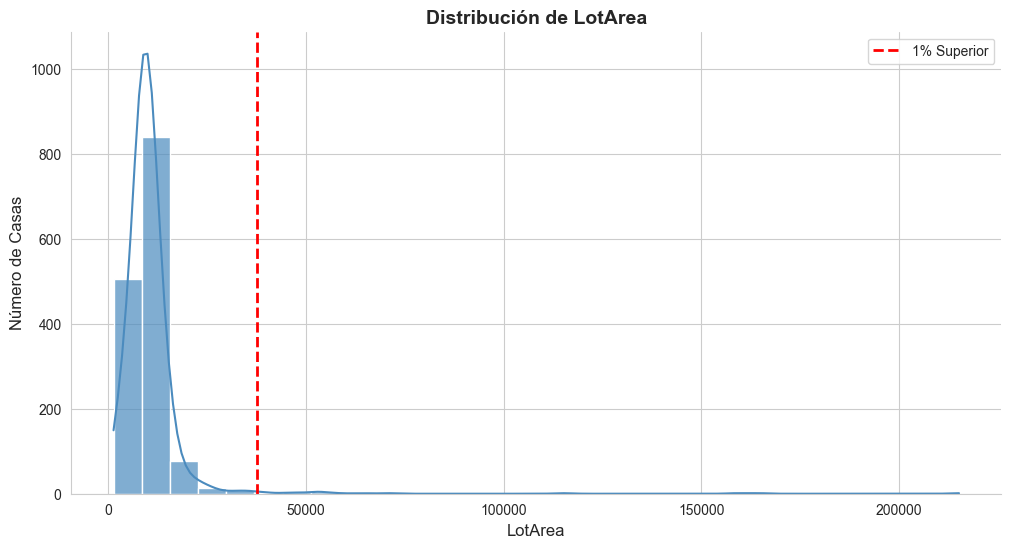

In [10]:
# Configuración de estilo
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))

# Crear el histograma
ax = sns.histplot(house_df['LotArea'], kde=True, color='#4B8BBE', bins=30, alpha=0.7)

# Marcar posibles outliers
plt.axvline(house_df['LotArea'].quantile(0.99), color='red', linestyle='--', linewidth=2, label='1% Superior')

# Personalización del gráfico
plt.title('Distribución de LotArea', fontsize=14, fontweight='bold')
plt.xlabel('LotArea', fontsize=12)
plt.ylabel('Número de Casas', fontsize=12)
plt.legend(fontsize=10, loc='upper right')
sns.despine()

# Mostrar la gráfica
plt.show()

En el momento de limpiar los datos decidiremos que hacer.

3. Qué variables crees que van a ser los más importantes? Como se comportan estos datos? Qué variable será nuestro target?

Las variables que creo que serán más importantes son:
- OverallQual
- GrLivArea
- GarageArea
- YearBuilt
- Neighborhood

C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\3669501390.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


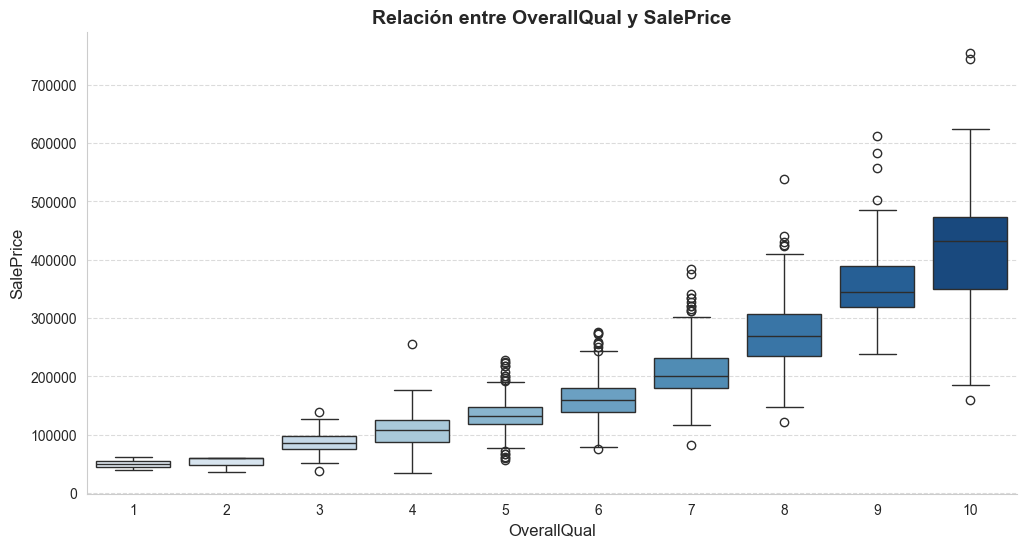

In [11]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    x=house_df['OverallQual'], 
    y=house_df['SalePrice'], 
    palette="Blues",
    hue=None
)
# plt.yscale('log')  # Para representarlo con escala logarítmica
plt.title('Relación entre OverallQual y SalePrice', fontsize=14, fontweight='bold')
plt.xlabel('OverallQual', fontsize=12)
plt.ylabel('SalePrice', fontsize=12)
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

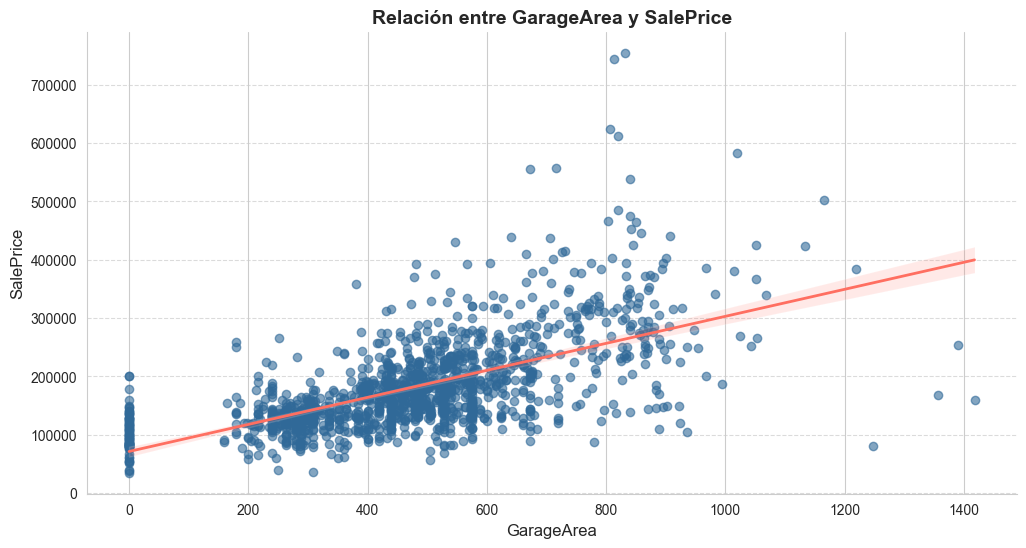

In [12]:
plt.figure(figsize=(12, 6))

# Gráfico de dispersión con línea de regresión
sns.regplot(
    data=house_df,
    x='GarageArea',
    y='SalePrice',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': '#FF6F61', 'linewidth': 2},
    color='#306998'
)

# Personalización
plt.title('Relación entre GarageArea y SalePrice', fontsize=14, fontweight='bold')
plt.xlabel('GarageArea', fontsize=12)
plt.ylabel('SalePrice', fontsize=12)
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

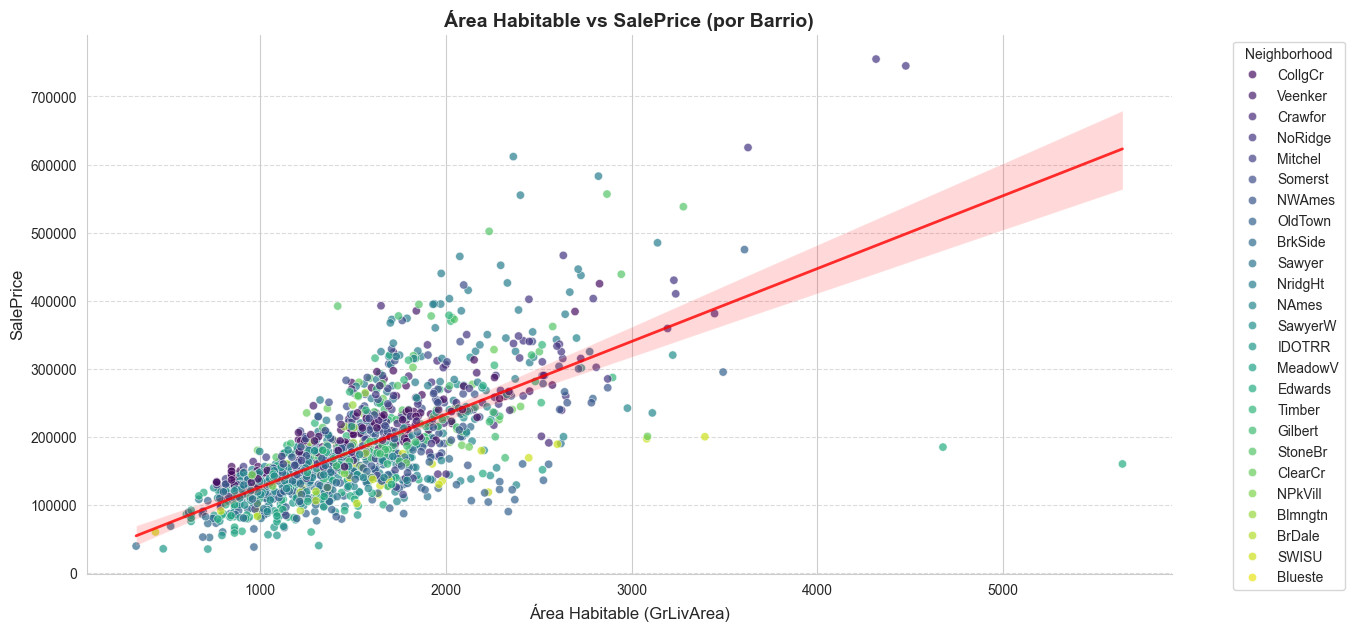

In [13]:
plt.figure(figsize=(14, 7))
sns.scatterplot(
    x=house_df['GrLivArea'], 
    y=house_df['SalePrice'], 
    hue=house_df['Neighborhood'], 
    palette="viridis", 
    alpha=0.7
)
sns.regplot(
    data=house_df, 
    x='GrLivArea', 
    y='SalePrice', 
    scatter=False, 
    color='red', 
    line_kws={"linewidth": 2, "alpha": 0.8}
)
# plt.yscale('log')  # Para representarlo con escala logarítmica
plt.title('Área Habitable vs SalePrice (por Barrio)', fontsize=14, fontweight='bold')
plt.xlabel('Área Habitable (GrLivArea)', fontsize=12)
plt.ylabel('SalePrice', fontsize=12)
plt.legend(title='Neighborhood', bbox_to_anchor=(1.05, 1), loc='upper left')
sns.despine()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

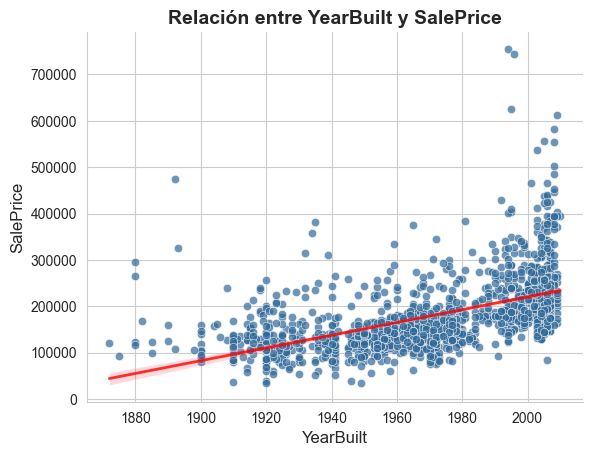

In [14]:
# Crear el gráfico de dispersión
ax = sns.scatterplot(
    data=house_df, 
    x='YearBuilt', 
    y='SalePrice', 
    alpha=0.7,
    color='#306998'
)

# Añadir línea de tendencia
sns.regplot(
    data=house_df, 
    x='YearBuilt', 
    y='SalePrice', 
    scatter=False,
    color='red', 
    line_kws={"linewidth": 2, "alpha": 0.8}
)

# Personalización general
plt.title('Relación entre YearBuilt y SalePrice', fontsize=14, fontweight='bold')
plt.xlabel('YearBuilt', fontsize=12)
plt.ylabel('SalePrice', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
sns.despine()

# Mostrar el gráfico
plt.show()

En general, son las variables que veo que tiene más correlación con nuestro target.

La variable objetivo es SalePrice (precio de venta de la vivienda).

4. Cuándo se construyeron los diferentes casas? Dibuja un gráfico para visualizarlo

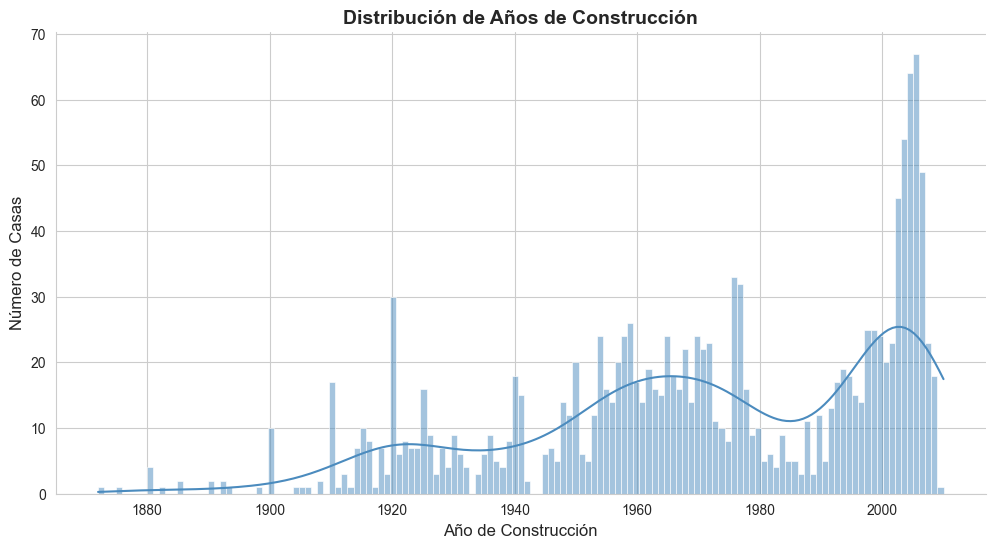

In [15]:
# Configuración de estilo
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))

# Calcular rango de años
min_year = house_df['YearBuilt'].min()
max_year = house_df['YearBuilt'].max()

# Crear el gráfico con barras año por año
ax = sns.histplot(
    data=house_df, 
    x='YearBuilt', 
    bins=max_year - min_year + 1,
    color='#4B8BBE', 
    kde=True
)

# Personalización general
plt.title('Distribución de Años de Construcción', fontsize=14, fontweight='bold')
plt.xlabel('Año de Construcción', fontsize=12)
plt.ylabel('Número de Casas', fontsize=12)
sns.despine()

# Mostrar el gráfico
plt.show()

Vemos que hay picos de construcción entre 1950 y 1970 (Baby boom), y luego el pico más grande al comienzo de los 2000s con la expansión urbanística y burbuja inmobiliaria.

5. Cuánto tiempo tardaron las diferentes casas en venderse? Dibuja un gráfico para visualizarlo

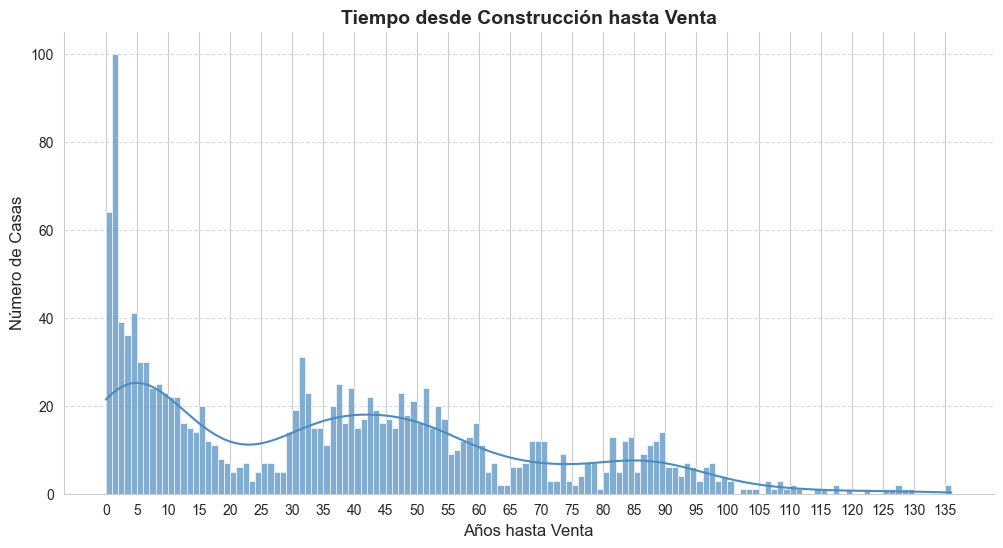

In [16]:
# Crear nueva variable
house_df['YearsToSell'] = house_df['YrSold'] - house_df['YearBuilt']

# Filtrar valores negativos (errores de datos)
house_df = house_df[house_df['YearsToSell'] >= 0]

# Configuración de estilo
sns.set_style("whitegrid")
plt.figure(figsize=(12, 6))

# Histograma con KDE
ax = sns.histplot(data=house_df, x='YearsToSell', bins=range(0, house_df['YearsToSell'].max() + 1), color='#4B8BBE', kde=True, alpha=0.7)

# Personalización
plt.title('Tiempo desde Construcción hasta Venta', fontsize=14, fontweight='bold')
plt.xlabel('Años hasta Venta', fontsize=12)
plt.ylabel('Número de Casas', fontsize=12)

# Ajustar los ticks del eje x de 5 en 5
plt.xticks(range(0, house_df['YearsToSell'].max() + 1, 5), fontsize=10)
plt.yticks(fontsize=10)

# Añadir líneas de rejilla
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Eliminar bordes superfluos
sns.despine()

# Mostrar el gráfico
plt.show()

Vemos que hay casas que se vendieron rápidamente y otras que tardaron mucho, quizás debido a herencias. He creado la variable YearsToSell, puede ser interesante para el modelo. Aquí vemos la correlación que tiene con SalePrice:

In [17]:
print(house_df[['YearsToSell', 'SalePrice']].corr())

             YearsToSell  SalePrice
YearsToSell      1.00000   -0.52335
SalePrice       -0.52335    1.00000


### Limpiar los datos
Cuando creamos un modelo, no hay forma de "mágicamente" contar al modelo que es lo que queremos. Tenemos que usar unos datos que representan bien nuestro problema y crear un modelo que predice algo que alinea con la respuesta que buscamos.

Si los datos son "sucios" (malos, con problemas, reflejan algo que no representa bien a nuestro problema) - nuestro modelo va a predecir cosas que no acaban de tener mucho sentido, no son de fiar o directamente son equivocadas.

Cosas que queremos evitar

* Datos que no tienen que ver con nuestro problema
* Datos que tienen poca muestra
* Outliers
* Nulos

1. Identifique los principales problemas que tienen las variables que parecen (por ahora) más interesantes para el modelo

- OverallQual: La mayoría de casas están en el rango 5-7 (calidad media) mientras que los valores extremos (1 y 10) tienen poca representación, lo cual podría sesgar el modelo.
- GarageArea: Casas sin garaje, por tanto valores nulos. Por otra parte, casas con garajes enormes, quizás habría que relacionar con la variable GarageCars.
- GrLivArea: Posibles outlier con casas excesivamente grandes.
- YearBuilt: Posibles outlier con pocas casas que son de antes de 1900. Por otra parte, casas que son viejas pero han sido remodeladas, quizás no estarían bien representadas, juntar con YearRemodeAdd puede ayudar.
- Neighborhood: Como categorizar la variable.

2. Arregla los problemas

In [18]:
# Outliers
# GrLivArea: Eliminar casas excesivamente grandes
house_df = house_df.loc[house_df['GrLivArea'] <= 4000]

# YearBuilt: Agrupar casas antiguas
house_df['YearBuilt'] = house_df['YearBuilt'].clip(lower=1900)

# GarageArea: Eliminar casas con garajes excesivamente grandes
upper_limit = house_df['GarageArea'].quantile(0.99)
house_df['GarageArea'] = house_df['GarageArea'].clip(upper=upper_limit)

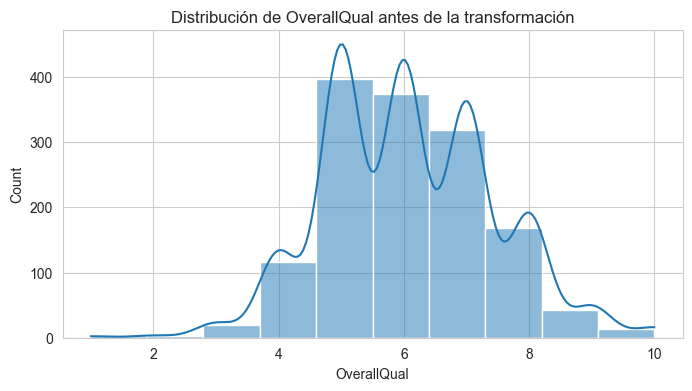

In [19]:
plt.figure(figsize=(8,4))
sns.histplot(house_df['OverallQual'], bins=10, kde=True)
plt.title("Distribución de OverallQual antes de la transformación")
plt.show()

In [20]:
def categorize_overallqual(x):
    if x <= 4:
        return 'Baja'
    elif x <= 8:
        return 'Media'
    else:
        return 'Alta'

house_df['OverallQual_Cat'] = house_df['OverallQual'].apply(categorize_overallqual)

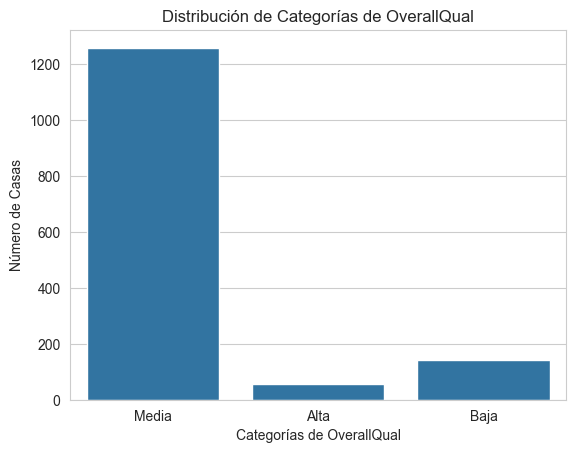

In [21]:
# Visualizar la distribución de las categorías de 'OverallQual'
sns.countplot(data=house_df, x='OverallQual_Cat')
plt.title('Distribución de Categorías de OverallQual')
plt.xlabel('Categorías de OverallQual')
plt.ylabel('Número de Casas')
plt.show()

In [22]:
# Contar cuántas casas hay por cada categoría
category_counts = house_df['OverallQual_Cat'].value_counts()
print(category_counts)

OverallQual_Cat
Media    1258
Baja      141
Alta       57
Name: count, dtype: int64


Creo que puede funcionar mejor la variable numérica que de forma catégorica porque creo que esto sesgaría aún más al modelo.

In [23]:
# Neighborhood
# Calcular el precio medio de SalePrice por barrio
neighborhood_price_mean = house_df.groupby('Neighborhood')['SalePrice'].mean().reset_index()
# Ordenar los barrios por el precio medio
neighborhood_price_mean_sorted = neighborhood_price_mean.sort_values(by='SalePrice', ascending=False)
# Extraer la lista de barrios ordenados según su precio medio
neighborhoods_sorted = neighborhood_price_mean_sorted['Neighborhood'].tolist()

C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\2845752417.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='SalePrice', y='Neighborhood', data=neighborhood_price_mean_sorted, palette='viridis')


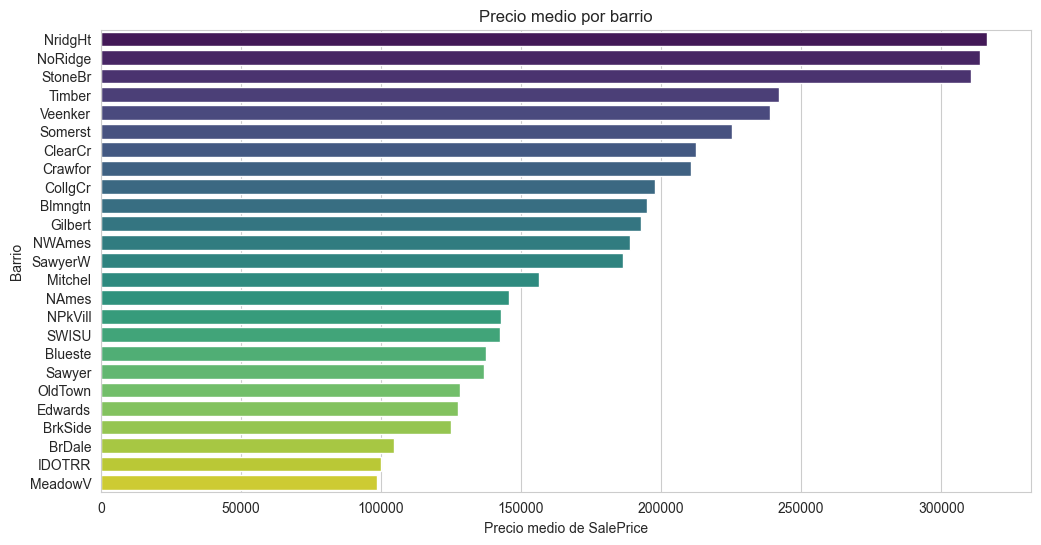

In [24]:
# Gráfico de barras de precios medios por barrio
plt.figure(figsize=(12, 6))
sns.barplot(x='SalePrice', y='Neighborhood', data=neighborhood_price_mean_sorted, palette='viridis')
plt.title('Precio medio por barrio')
plt.xlabel('Precio medio de SalePrice')
plt.ylabel('Barrio')
plt.show()

In [25]:
# Crear el encoder de tipo ordinal usando el orden de los barrios basado en su precio medio
encoder = OrdinalEncoder(categories=[neighborhoods_sorted])
# Codificar la columna 'Neighborhood' en valores numéricos
house_df['Neighborhood'] = encoder.fit_transform(house_df[['Neighborhood']])

De esta manera hemos ordenado por el precio medio de venta los barrios. Esto más adelante comentaré que se tendría que haber hecho después de dividir los datos en train/validation/test.

In [26]:
# Variable categórica que indica si la casa tiene garaje
house_df['HasGarage'] = (house_df['GarageArea'] > 0).astype(int)

Esta variable al final tampoco será utilizada en el modelo.

3. Borra todos los datos que no son relevantes para el problema - simplifica los datos

In [27]:
# Eliminar las ventas no normales y los tipos de venta no estándar
house_df.drop(house_df[house_df["SaleType"] != "WD"].index, inplace=True)
house_df.drop(house_df[house_df["SaleCondition"] != "Normal"].index, inplace=True)

In [28]:
# Outliers
# LotArea:
upper_limit = house_df['LotArea'].quantile(0.99)
house_df['LotArea'] = house_df['LotArea'].clip(upper=upper_limit)

# Guardar una copia del SalePrice original antes de modificarlo
house_df['SalePrice_Original'] = house_df['SalePrice'].copy()

# # SalePrice: Eliminar casas con precios excesivamente altos
upper_limit = house_df['SalePrice'].quantile(0.95)
# SalePrice: Eliminar casas con precios excesivamente bajos
lower_limit = house_df['SalePrice'].quantile(0.05)
house_df['SalePrice'] = house_df['SalePrice'].clip(lower=lower_limit, upper=upper_limit)

print(f"Lower limit (5th percentile): ${lower_limit:,.2f}")
print(f"Upper limit (95th percentile): ${upper_limit:,.2f}")

Lower limit (5th percentile): $90,000.00
Upper limit (95th percentile): $307,200.00


C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\1373247907.py:13: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  house_df['SalePrice'] = house_df['SalePrice'].clip(lower=lower_limit, upper=upper_limit)


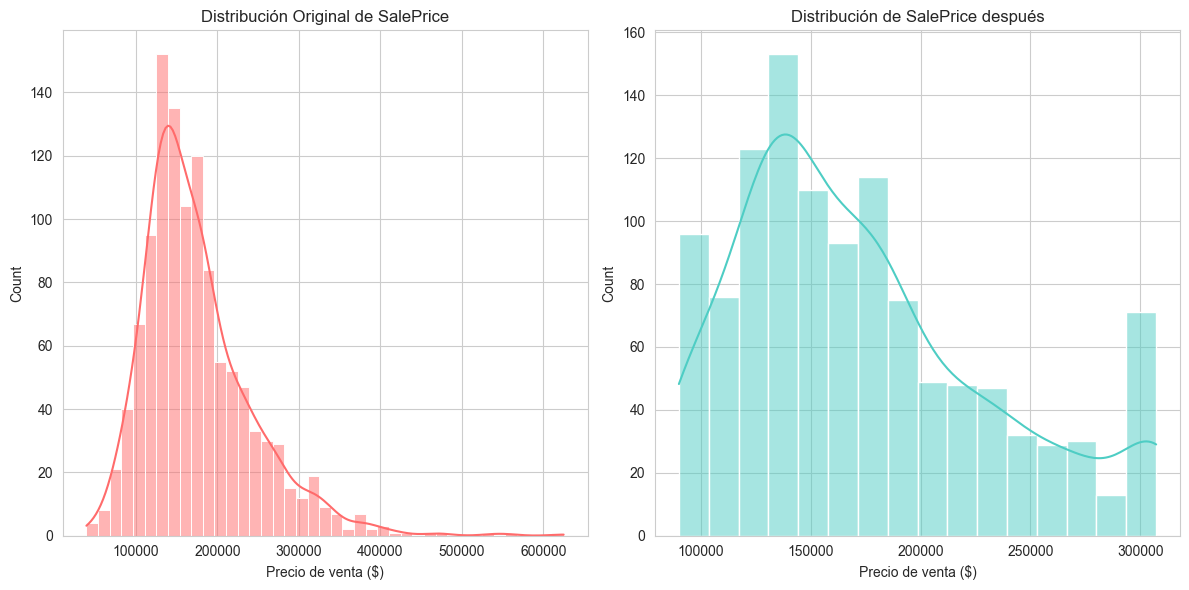

In [29]:
# Crear la figura
plt.figure(figsize=(12, 6))

# Histograma de SalePrice antes de clip()
plt.subplot(1, 2, 1)
sns.histplot(house_df['SalePrice_Original'], kde=True, color='#FF6B6B')
plt.title('Distribución Original de SalePrice', fontsize=12)
plt.xlabel('Precio de venta ($)')

# Histograma de SalePrice después de clip()
plt.subplot(1, 2, 2)
sns.histplot(house_df['SalePrice'], kde=True, color='#4ECDC4')
plt.title('Distribución de SalePrice después', fontsize=12)
plt.xlabel('Precio de venta ($)')

plt.tight_layout()
plt.show()

Después de hacer pruebas con el modelo, para evitar que precios extremadamente altos/bajos distorsionen el modelo, he tratado el outlier del 5% máximo/mínimo de SalePrice poniendole un límite. El modelo estará optimizado para predecir precios dentro de ese rango. Sin embargo, podría no ser tan preciso al estimar precios de casas de lujo. Por otra parte, casas muy baratas (< $90,000) quizás no nos interesan mucho.

In [30]:
# Tratando nulos de FireplaceQu
house_df['FireplaceQu'] = house_df['FireplaceQu'].fillna('NA')

In [31]:
# # Conteo de valores nulos
house_df.isnull().sum()

Id                       0
MSSubClass               0
MSZoning                 0
LotFrontage            231
LotArea                  0
Street                   0
Alley                 1091
LotShape                 0
LandContour              0
Utilities                0
LotConfig                0
LandSlope                0
Neighborhood             0
Condition1               0
Condition2               0
BldgType                 0
HouseStyle               0
OverallQual              0
OverallCond              0
YearBuilt                0
YearRemodAdd             0
RoofStyle                0
RoofMatl                 0
Exterior1st              0
Exterior2nd              0
MasVnrType             713
MasVnrArea               4
ExterQual                0
ExterCond                0
Foundation               0
BsmtQual                30
BsmtCond                30
BsmtExposure            31
BsmtFinType1            30
BsmtFinSF1               0
BsmtFinType2            31
BsmtFinSF2               0
B

Podemos ver que quedan aún nulos en nuestro dataset, pero esas variables no las utilizaremos en el modelo. Quizás podríamos haber limpiado ya el dataset por si las tuviesemos que usar en otro tipo de ejercicio, pero por ahora no parecen interesantes.

## Preparación de los datos para el modelo
Ahora que entendemos bien los datos, tomamos un paso más directo hacia la creación de nuestro modelo preparando los datos para el entrenamiento.

### Relevancia de variables
Por norma general, queremos incluir variables que son importantes en la predicción de nuestro target:

* Tener menos variables más relevantes suele ser mejor - porque simplifica el modelo
* Si no tenemos variables relevantes, los resultados del modelo van a ser malos

Para analizar la relevancia, normalmente miramos que haya "correlaciones" entre diferentes variables y el target. Hay muchas formas de analizar estas "correlaciones", como por ejemplo:

* Coeficiente de correlación (variables continuas)
* La media del target para cada valor del variable (variables NO continuas)

1. Qué variables son los más relevantes? Analiza la relevancia para comprobarlo

Tenemos que diferenciar entre variables númericas y variables categóricas:

In [32]:
# Seleccionar solo las columnas numéricas
numeric_columns = house_df.select_dtypes(include=['float64', 'int64']).columns

# Calcular la matriz de correlación solo para las columnas numéricas
correlation_matrix = house_df[numeric_columns].corr()
correlation_with_price = correlation_matrix['SalePrice'].sort_values(ascending=False)
print(correlation_with_price)

SalePrice             1.000000
SalePrice_Original    0.966283
OverallQual           0.797348
GrLivArea             0.732764
GarageCars            0.653415
GarageArea            0.644232
TotalBsmtSF           0.619958
1stFlrSF              0.599460
FullBath              0.589741
YearBuilt             0.545748
TotRmsAbvGrd          0.524590
YearRemodAdd          0.511367
GarageYrBlt           0.491271
Fireplaces            0.487660
MasVnrArea            0.404780
LotArea               0.396484
BsmtFinSF1            0.380905
LotFrontage           0.359483
2ndFlrSF              0.351497
OpenPorchSF           0.346559
WoodDeckSF            0.336980
HalfBath              0.310550
HasGarage             0.256979
BsmtFullBath          0.235840
BedroomAbvGr          0.222107
BsmtUnfSF             0.211967
ScreenPorch           0.116297
3SsnPorch             0.037141
MoSold                0.029852
BsmtFinSF2            0.022579
PoolArea              0.021849
YrSold                0.003163
MiscVal 

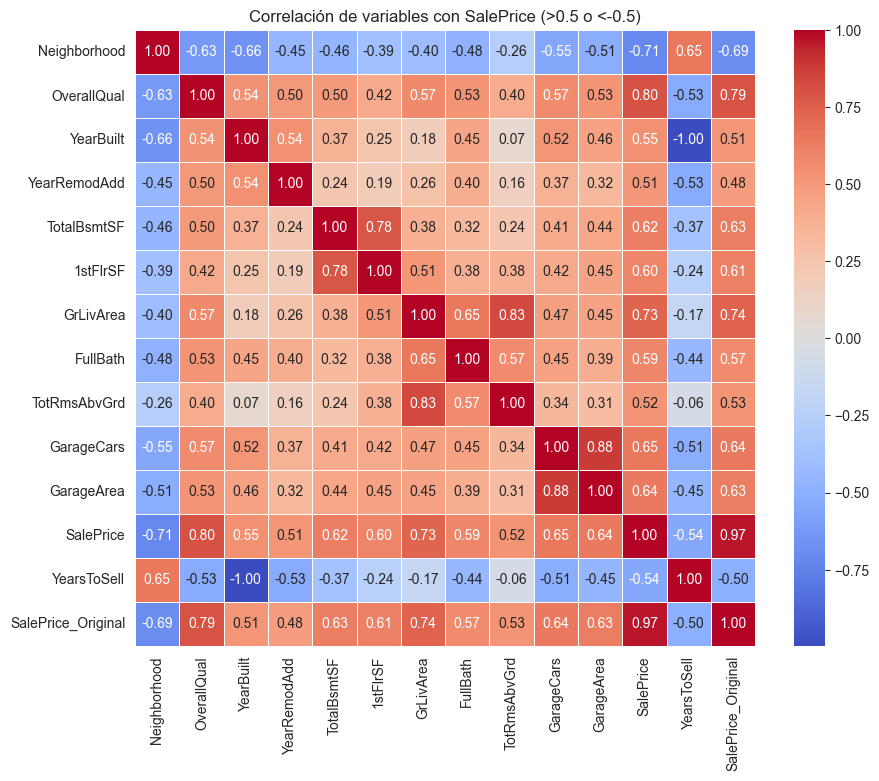

In [33]:
# Calcular la correlación de todas las variables
corr_matrix = house_df[numeric_columns].corr()

# Filtrar las variables que tienen una correlación con SalePrice mayor a 0.5 o menor a -0.5
corr_with_saleprice = corr_matrix['SalePrice'].abs() > 0.5

# Seleccionar solo las columnas que cumplen con la condición
selected_corr_vars = corr_matrix.columns[corr_with_saleprice]

# Crear la matriz de correlación con solo las variables seleccionadas
filtered_corr_matrix = corr_matrix[selected_corr_vars].loc[selected_corr_vars]

# Crear el heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(filtered_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlación de variables con SalePrice (>0.5 o <-0.5)")
plt.show()

Estas serían las variables numéricas con más importancia. Hay algunas variables que son muy parecidas así que habrá que descartar.

In [34]:
def categorize_correlation(df, target):
    """
    Calcula la correlación de variables categóricas con el target (SalePrice).
    Para cada variable categórica, devuelve la media de SalePrice por categoría.
    
    df: DataFrame con los datos
    target: nombre de la variable objetivo (e.g., 'SalePrice')
    """
    correlation_dict = {}

    # Iterar sobre todas las columnas categóricas
    for column in df.select_dtypes(include=['object', 'category']).columns:
        # Calcular la media de SalePrice para cada categoría
        category_mean = df.groupby(column)[target].mean()
        correlation_dict[column] = category_mean

    return correlation_dict

# Llamar a la función y obtener el resultado
correlation_result = categorize_correlation(house_df, 'SalePrice')

# Ver el resultado
for col, corr in correlation_result.items():
    print(f"Correlación para la variable {col}:")
    print(corr)
    print("\n")


Correlación para la variable MSZoning:
MSZoning
C (all)    111950.000000
FV         206619.736842
RH         122509.090909
RL         181603.604324
RM         127437.693989
Name: SalePrice, dtype: float64


Correlación para la variable Street:
Street
Grvl    161037.500000
Pave    173232.322078
Name: SalePrice, dtype: float64


Correlación para la variable Alley:
Alley
Grvl    126974.487805
Pave    169451.074074
Name: SalePrice, dtype: float64


Correlación para la variable LotShape:
LotShape
IR1    194278.816537
IR2    213600.000000
IR3    202262.857143
Reg    159867.770178
Name: SalePrice, dtype: float64


Correlación para la variable LandContour:
LandContour
Bnk    147792.708333
HLS    196790.000000
Low    215486.666667
Lvl    172352.946463
Name: SalePrice, dtype: float64


Correlación para la variable Utilities:
Utilities
AllPub    173190.234685
Name: SalePrice, dtype: float64


Correlación para la variable LotConfig:
LotConfig
Corner     173154.403941
CulDSac    203726.129870
FR2  

C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\25242297.py:10: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x=house_df[var], y=house_df['SalePrice'], estimator='mean', ci=None, palette='viridis')
C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\25242297.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=house_df[var], y=house_df['SalePrice'], estimator='mean', ci=None, palette='viridis')
C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\25242297.py:10: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x=house_df[var], y=house_df['SalePrice'], estimator='mean', ci=None, palette='viridis')
C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\25242297.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is dep

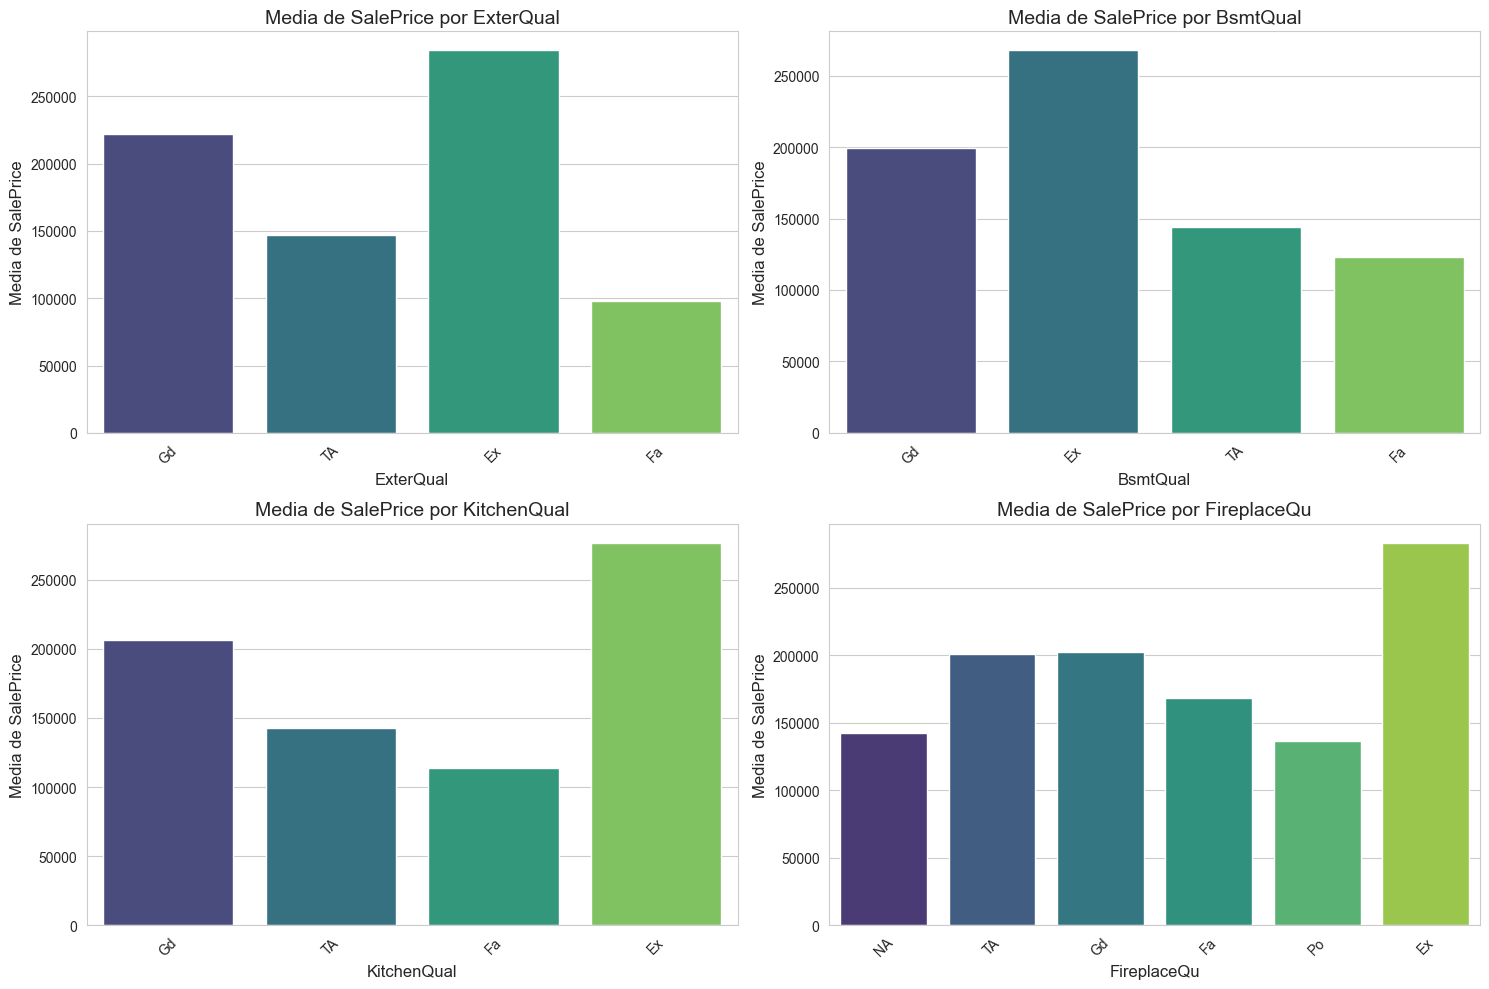

In [35]:
# Variables relevantes que queremos analizar
relevant_vars = ['ExterQual', 'BsmtQual', 'KitchenQual', 'FireplaceQu']

# Crear una figura con un tamaño adecuado
plt.figure(figsize=(15, 10))

# Graficar cada variable relevante
for i, var in enumerate(relevant_vars):
    plt.subplot(2, 2, i + 1)  # Ajustar el número de subgráficos
    sns.barplot(x=house_df[var], y=house_df['SalePrice'], estimator='mean', ci=None, palette='viridis')
    plt.title(f'Media de SalePrice por {var}', fontsize=14)
    plt.xlabel(var, fontsize=12)
    plt.ylabel('Media de SalePrice', fontsize=12)
    plt.xticks(rotation=45)

plt.tight_layout()  # Ajustar para que no se solapen los gráficos
plt.show()

De las variables categóricas, las de quality tienen bastante correlación con el precio. También imagino que estará muy relacionado con la variable OverallQual, asi que alomejor no son tan importantes.

In [36]:
house_df['MSSubClass'] = house_df['MSSubClass'].astype('category')

ms_subclass_counts = house_df['MSSubClass'].value_counts().sort_index()
print(ms_subclass_counts)

MSSubClass
20     413
30      55
40       4
45      12
50     121
60     240
70      51
75      13
80      49
85      17
90      35
120     65
160     52
180      8
190     24
Name: count, dtype: int64


In [37]:
ms_subclass_saleprice = house_df.groupby('MSSubClass')['SalePrice'].mean().sort_values(ascending=False)
print(ms_subclass_saleprice)

MSSubClass
60     221852.179167
120    190088.923077
75     185415.384615
20     174579.387409
80     170131.632653
70     166853.823529
40     158750.000000
50     147911.008264
85     144129.411765
160    139948.076923
90     130550.428571
190    129412.500000
45     110258.333333
180    104250.000000
30     103227.272727
Name: SalePrice, dtype: float64


C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\1262213215.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ms_subclass_saleprice = house_df.groupby('MSSubClass')['SalePrice'].mean().sort_values(ascending=False)


In [38]:
house_df['MSZoning'] = house_df['MSZoning'].astype('category')

mszoning_counts = house_df['MSZoning'].value_counts()
print(mszoning_counts)

MSZoning
RL         925
RM         183
FV          38
RH          11
C (all)      2
Name: count, dtype: int64


In [39]:
mszoning_saleprice = house_df.groupby('MSZoning')['SalePrice'].mean().sort_values(ascending=False)
print(mszoning_saleprice)

MSZoning
FV         206619.736842
RL         181603.604324
RM         127437.693989
RH         122509.090909
C (all)    111950.000000
Name: SalePrice, dtype: float64


C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\377757456.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mszoning_saleprice = house_df.groupby('MSZoning')['SalePrice'].mean().sort_values(ascending=False)


MSSubClass es una variable numérica pero en realidad es categorica por lo que no funcionaba bien con los otros analisis que habíamos hecho. Aparte, hay otra variable interesante que sería MSZoning. Puede que las utilizemos ya que parecen relevantes. Ahora le aplicaremos Target encoding como había hecho con los barrios.

In [40]:
# Pasar a string
house_df['MSSubClass'] = house_df['MSSubClass'].astype(str)

# Calcular el precio medio de SalePrice por cada categoría de MSSubClass
ms_subclass_price_mean = house_df.groupby('MSSubClass')['SalePrice'].mean().reset_index()

# Ordenar las categorías de MSSubClass por el precio medio, de mayor a menor
ms_subclass_price_mean_sorted = ms_subclass_price_mean.sort_values(by='SalePrice', ascending=False)

# Extraer la lista de categorías ordenadas
ms_subclasses_sorted = ms_subclass_price_mean_sorted['MSSubClass'].tolist()

# Crear un encoder ordinal usando el orden de MSSubClass basado en el precio medio
encoder_subclass = OrdinalEncoder(categories=[ms_subclasses_sorted])

# Codificar la columna 'MSSubClass' en valores numéricos según el orden definido
house_df['MSSubClass'] = encoder_subclass.fit_transform(house_df[['MSSubClass']])

In [41]:
mszoning_price_mean = house_df.groupby('MSZoning')['SalePrice'].mean().reset_index()
mszoning_price_mean_sorted = mszoning_price_mean.sort_values(by='SalePrice', ascending=False)
mszoning_sorted = mszoning_price_mean_sorted['MSZoning'].tolist()
encoder_zoning = OrdinalEncoder(categories=[mszoning_sorted])
house_df['MSZoning'] = encoder_zoning.fit_transform(house_df[['MSZoning']])

C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\237810290.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mszoning_price_mean = house_df.groupby('MSZoning')['SalePrice'].mean().reset_index()


2. Podemos crear algunas variables para mejorar la relevancia?

Teniendo en cuenta las variables numéricas con mayor relevancia podríamos unir las que refieren al area total de la casa (1er piso, 2ndo, sotáno y garaje).

In [42]:
house_df["TotalArea"] = house_df["TotalBsmtSF"] + house_df["1stFlrSF"] + house_df["2ndFlrSF"] + house_df["GarageArea"]

In [43]:
print(house_df["TotalArea"].describe())

count    1159.000000
mean     2970.227265
std       861.686131
min       334.000000
25%      2371.000000
50%      2884.000000
75%      3482.500000
max      6974.000000
Name: TotalArea, dtype: float64


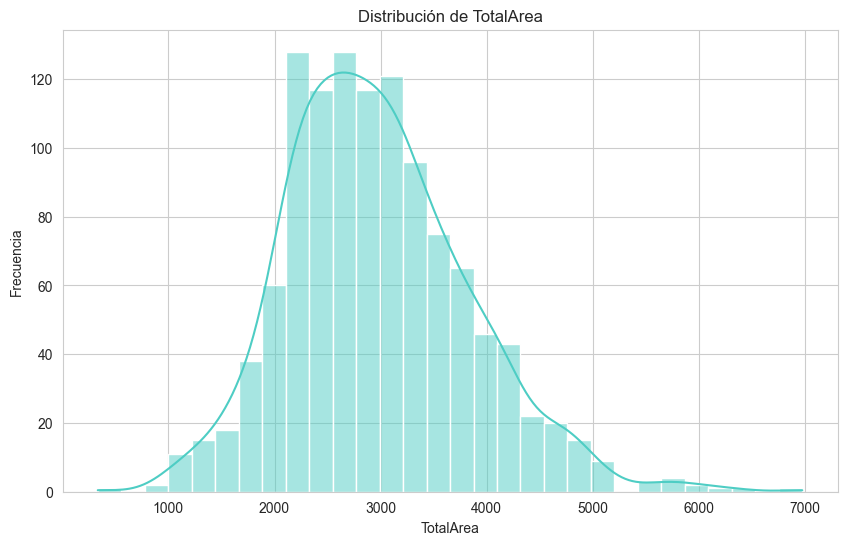

In [44]:
plt.figure(figsize=(10, 6))
sns.histplot(house_df["TotalArea"], kde=True, bins=30, color='#4ECDC4')
plt.title('Distribución de TotalArea')
plt.xlabel('TotalArea')
plt.ylabel('Frecuencia')
plt.show()


In [45]:
print("Percentil 1:", house_df["TotalArea"].quantile(0.01))
print("Percentil 5:", house_df["TotalArea"].quantile(0.05))
print("Percentil 95:", house_df["TotalArea"].quantile(0.95))
print("Percentil 99:", house_df["TotalArea"].quantile(0.99))

Percentil 1: 1184.12
Percentil 5: 1727.7
Percentil 95: 4521.399999999999
Percentil 99: 5317.9000000000215


In [46]:
house_df["TotalArea"] = house_df["TotalArea"].clip(lower=1200, upper=5000)

Tratamos los posibles outlier dejando un rango entre 1200 y 5000.

In [47]:
total_area_corr = house_df[["TotalArea", 'SalePrice']].corr()
print(f"La correlación entre 'TotalArea' y 'SalePrice' es de {total_area_corr['TotalArea']['SalePrice']:.2f}.")

La correlación entre 'TotalArea' y 'SalePrice' es de 0.86.


Por otra parte, podriamos crear una variable que indicase si una casa ha sido renovada o no.

In [48]:
house_df['Renovated'] = (house_df['YearRemodAdd'] > house_df['YearBuilt']).astype(int)

C:\Users\alanm\AppData\Local\Temp\ipykernel_5580\1926040882.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Renovated', y='SalePrice', data=house_df, estimator='mean', errorbar=None, palette='coolwarm')


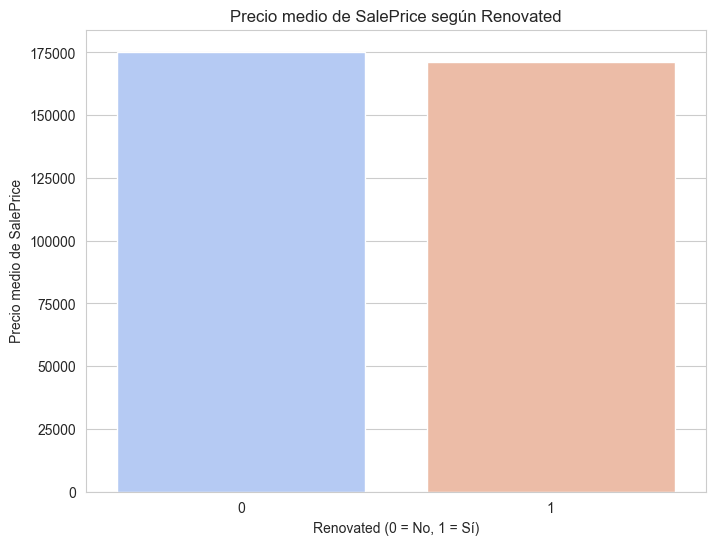

In [49]:
plt.figure(figsize=(8, 6))
sns.barplot(x='Renovated', y='SalePrice', data=house_df, estimator='mean', errorbar=None, palette='coolwarm')
plt.title('Precio medio de SalePrice según Renovated')
plt.xlabel('Renovated (0 = No, 1 = Sí)')
plt.ylabel('Precio medio de SalePrice')
plt.show()

Quizás no es tan interesante como pensaba.

También podría ser interesante tener la cantidad de baños.

In [50]:
house_df['TotalBathrooms'] = (house_df['FullBath'] +
                              0.5 * house_df['HalfBath'] +
                              house_df['BsmtFullBath'] +
                              0.5 * house_df['BsmtHalfBath'])

In [51]:
corr_bath = house_df['TotalBathrooms'].corr(house_df['SalePrice'])
print("Correlación entre TotalBathrooms y SalePrice:", corr_bath)

Correlación entre TotalBathrooms y SalePrice: 0.6718621918531197


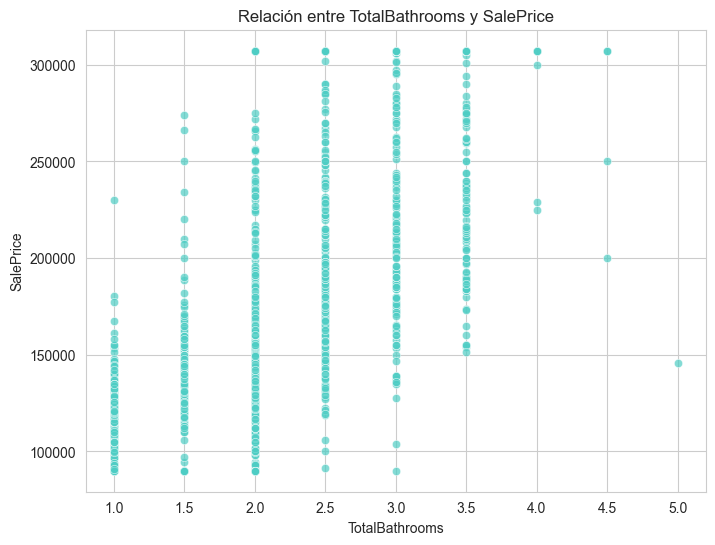

In [52]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='TotalBathrooms', y='SalePrice', data=house_df, color='#4ECDC4', alpha=0.7)
plt.title('Relación entre TotalBathrooms y SalePrice')
plt.xlabel('TotalBathrooms')
plt.ylabel('SalePrice')
plt.show()

In [53]:
# Elimino la fila con 5 baños como posible outlier:
house_df = house_df[house_df['TotalBathrooms'] != 5]

Como he comentado antes, las variables sobre la calidad tenían bastante correlación con el precio. Podemos probar a combinarlas:

In [54]:
quality_mapping = {
    'Ex': 5,
    'Gd': 4,
    'TA': 3,
    'Fa': 2,
    'Po': 1,
    'NA': 0
}

for col in ['ExterQual', 'BsmtQual', 'KitchenQual', 'FireplaceQu']:
    house_df[col] = house_df[col].map(quality_mapping)

In [55]:
for col in ['ExterQual', 'BsmtQual', 'KitchenQual', 'FireplaceQu']:
    corr = house_df[col].corr(house_df['SalePrice'])
    print(f"Correlación entre {col} y SalePrice:", corr)


Correlación entre ExterQual y SalePrice: 0.661509471951894
Correlación entre BsmtQual y SalePrice: 0.6048023801016263
Correlación entre KitchenQual y SalePrice: 0.6617993504534533
Correlación entre FireplaceQu y SalePrice: 0.5199704037335203


In [56]:
# 2. Crear la variable MinQuality usando el mínimo de las calidades
house_df['MinQuality'] = house_df[['ExterQual', 'BsmtQual', 'KitchenQual', 'FireplaceQu']].apply(lambda x: min(x), axis=1)

# 3. Calcular la correlación de MinQuality con SalePrice
corr_min_quality = house_df['MinQuality'].corr(house_df['SalePrice'])
print("Correlación entre MinQuality y SalePrice:", corr_min_quality)

Correlación entre MinQuality y SalePrice: 0.5762587809701747


In [57]:
corr_value = house_df['MinQuality'].corr(house_df['OverallQual'])
print("Correlación entre MinQuality y OverallQual:", corr_value)

Correlación entre MinQuality y OverallQual: 0.49373363567042133


Creía que quizás tendrían una correlación más grande. Igualmente, después de hacer pruebas no la he utilizado en el modelo.

### Train y test
Dividir los datos en train y test (o train, test y validación) es un paso fundamental para la correcta evaluación de nuestro modelo. Buscamos replicar el efecto de "tener datos nuevos". 

Nota: En realidad, lo más correcto seria dividir en train / test ANTES de analizar relevancias - pero simplificamos un poco por ahora.

Nota 2: Si dividimos de forma *random* es importante fijar el seed (te vas a volver loco si no)

1. Qué variables quieres elegir para tu `X` final?

In [58]:
features_chosen = [
    "OverallQual",
    "GrLivArea",
    "YearBuilt",
    "Neighborhood",
    "TotalArea",
    "TotalBathrooms",
    "Renovated",
    "MSSubClass",
    "MSZoning"
]

target = "SalePrice"

In [59]:
X = house_df[features_chosen]
y = house_df[target]

2. Divide los datos en train / test

In [60]:
YEAR_SOLD_VALIDATION_CUTOFF = 2009
YEAR_SOLD_TEST_CUTOFF = 2010

# Dividir los datos en train, validación y test
train_df = house_df[house_df['YrSold'] < YEAR_SOLD_VALIDATION_CUTOFF]
validation_df = house_df[
    (house_df['YrSold'] >= YEAR_SOLD_VALIDATION_CUTOFF) & (house_df['YrSold'] < YEAR_SOLD_TEST_CUTOFF)
]
test_df = house_df[house_df['YrSold'] >= YEAR_SOLD_TEST_CUTOFF]

# Separar las variables predictoras (X) y la variable objetivo (y)
X_train = train_df[features_chosen]
X_validation = validation_df[features_chosen]
X_test = test_df[features_chosen]

y_train = train_df[target]
y_validation = validation_df[target]
y_test = test_df[target]

# Mostrar resultados de la división
print("División del conjunto de datos:")
print(f"Conjunto de entrenamiento (antes de {YEAR_SOLD_VALIDATION_CUTOFF}): {len(train_df)} registros.")
print(f"Conjunto de validación ({YEAR_SOLD_VALIDATION_CUTOFF}-{YEAR_SOLD_TEST_CUTOFF}): {len(validation_df)} registros.")
print(f"Conjunto de prueba (a partir de {YEAR_SOLD_TEST_CUTOFF}): {len(test_df)} registros.")


División del conjunto de datos:
Conjunto de entrenamiento (antes de 2009): 731 registros.
Conjunto de validación (2009-2010): 277 registros.
Conjunto de prueba (a partir de 2010): 150 registros.


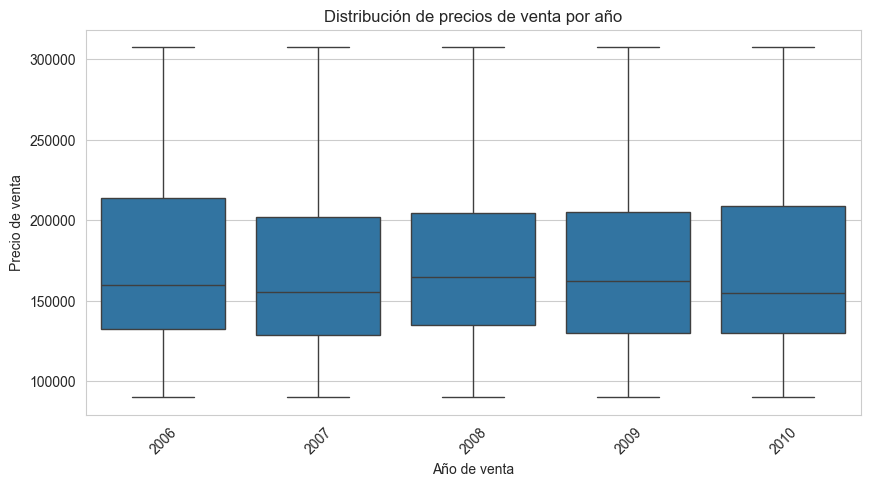

In [61]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=house_df["YrSold"], y=house_df["SalePrice"])
plt.title("Distribución de precios de venta por año")
plt.xlabel("Año de venta")
plt.ylabel("Precio de venta")
plt.xticks(rotation=45)
plt.show()

Podemos observar que la distribución de precios por año es bastante pareja por lo que dividir los datos por años puede ser una gran opción.

## Modelado
Ahora vamos a entrenar el modelo. Si has hecho lo anterior bien, este paso es muy sencillo. Normalmente incluimos aquí optimizaciones del modelo, pero para el primer ejercicio esto es de menor importancia.

### Entrenar el modelo
La parta más sexy, pero por ahora lo más sencillo. Tiramos de librerías de modelos ya hechos para simplificarnos la vida.  

1. Crea un modelo de regresión

In [62]:
model = LinearRegression()
model = model.fit(X_train, y_train)

2. Generar predicciones para tu conjunto de test

In [63]:
y_predict = model.predict(X_validation)

### Evaluar el modelo
No vamos a dedicar mucho esfuerzo en este paso por ahora, pero es fundamental evaluar las predicciones que hemos generado. El objetivo es entender lo bueno que es nuestro modelo, para entender si podemos fiar de los resultados y usarlo para responder a nuestro problema.

1. Elige las métricas para tu evaluación

He elegido:
- Mean absolute error (MAE)
- Median absolute error (MedAE)
- Root mean squared error (RMSE)
- R2 (Coeficiente de determinación)

2. Evalúa las predicciones generadas

In [64]:
# Métricas sobre el conjunto de validación
print("Métricas del conjunto de validación")
print()

# Precio medio del conjunto de validación
mean_validation_sale_price = y_validation.mean()
print(f"Precio medio de venta: ${mean_validation_sale_price:,.2f}")

# Baseline: modelo que predice siempre el precio medio
baseline = np.full(len(y_validation), mean_validation_sale_price)

# Cálculo de métricas para el modelo base (baseline)
baseline_mae = metrics.mean_absolute_error(y_validation, baseline)
baseline_medae = metrics.median_absolute_error(y_validation, baseline)
baseline_rmse = metrics.root_mean_squared_error(y_validation, baseline)
baseline_r2 = metrics.r2_score(y_validation, baseline)

print("\nMétricas del modelo base (baseline)")
print(f"MAE: ${baseline_mae:,.2f} ({(baseline_mae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${baseline_medae:,.2f} ({(baseline_medae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${baseline_rmse:,.2f} ({(baseline_rmse / mean_validation_sale_price * 100):.2f}% de error)")
print(f"R²: {baseline_r2:.4f}")

# Cálculo de métricas para el modelo entrenado
model_mae = metrics.mean_absolute_error(y_validation, y_predict)
model_medae = metrics.median_absolute_error(y_validation, y_predict)
model_rmse = metrics.root_mean_squared_error(y_validation, y_predict)
model_r2 = metrics.r2_score(y_validation, y_predict)

print("\nMétricas del modelo entrenado")
print(f"MAE: ${model_mae:,.2f} ({(model_mae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${model_medae:,.2f} ({(model_medae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${model_rmse:,.2f} ({(model_rmse / mean_validation_sale_price * 100):.2f}% de error)")
print(f"R²: {model_r2:.4f}")


Métricas del conjunto de validación

Precio medio de venta: $173,991.23

Métricas del modelo base (baseline)
MAE: $49,010.28 (28.17% de error)
MedAE: $40,991.23 (23.56% de error)
RMSE: $60,970.57 (35.04% de error)
R²: 0.0000

Métricas del modelo entrenado
MAE: $16,561.66 (9.52% de error)
MedAE: $12,951.76 (7.44% de error)
RMSE: $21,299.03 (12.24% de error)
R²: 0.8780


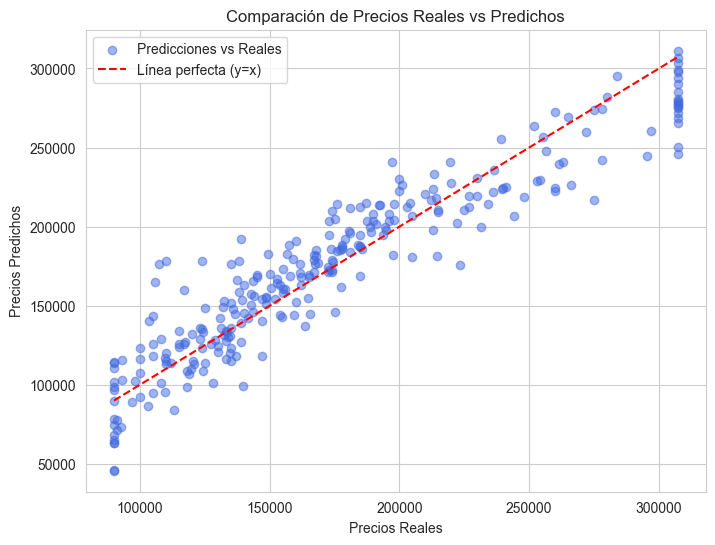

In [65]:
plt.figure(figsize=(8, 6))
plt.scatter(y_validation, y_predict, alpha=0.5, label="Predicciones vs Reales", color="royalblue")
plt.plot([min(y_validation), max(y_validation)], [min(y_validation), max(y_validation)], '--', color="red", label="Línea perfecta (y=x)")

plt.xlabel("Precios Reales")
plt.ylabel("Precios Predichos")
plt.title("Comparación de Precios Reales vs Predichos")
plt.legend()
plt.grid(True)

plt.show()

3. El modelo funciona? Se podría utilizar para ayudarnos con el problema que tenemos?

Después de hacer distintas pruebas con algunas variables, con el resultado que me he quedado creo que podría decir que el modelo funciona en general de manera satisfactoria. Como se ha visto en el gráfico anterior, las casas más caras y mas baratas puede que tenga un margen de error un poco más alto, pero con las casas de precio medio (que puede que sean las que más nos interesan) tiene un margen de error bastante bajo.

Hay que tener en cuenta que el modelo no hace predicciones perfectas y siempre existe un margen de error. Dicho esto, podríamos usar nuestro modelo para identificar casas potencialmente infravaloradas (chollos) más fácilmente que otra persona la cual no tenga acceso a nuestro modelo.

En resumen, el modelo funciona lo suficientemente bien como para ser una herramienta de apoyo en la toma de decisiones al comprar una casa, siempre y cuando se tenga en cuenta su margen de error en el proceso de evaluación.

### Anexo

Aquí voy a tratar temas que no están en el enunciado.

Primeramente las pruebas que hecho con otro tipo de modelos:

In [66]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, median_absolute_error, root_mean_squared_error, r2_score

# Crear el modelo
dt_model = DecisionTreeRegressor(random_state=42)

# Entrenar el modelo
dt_model.fit(X_train, y_train)

# Realizar predicciones
y_dt_predict = dt_model.predict(X_validation)

# Calcular las métricas
dt_mae = mean_absolute_error(y_validation, y_dt_predict)
dt_medae = median_absolute_error(y_validation, y_dt_predict)
dt_rmse = root_mean_squared_error(y_validation, y_dt_predict)
dt_r2 = r2_score(y_validation, y_dt_predict)

# Imprimir las métricas
print("Métricas del modelo de Árbol de Decisión:")
print(f"MAE: ${dt_mae:,.2f} ({(dt_mae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${dt_medae:,.2f} ({(dt_medae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${dt_rmse:,.2f} ({(dt_rmse / mean_validation_sale_price * 100):.2f}% de error)")
print(f"R²: {dt_r2:.4f}")

Métricas del modelo de Árbol de Decisión:
MAE: $20,664.32 (11.88% de error)
MedAE: $16,000.00 (9.20% de error)
RMSE: $28,777.47 (16.54% de error)
R²: 0.7772


In [67]:
from sklearn.ensemble import RandomForestRegressor

# Crear el modelo
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Entrenar el modelo
rf_model.fit(X_train, y_train)

# Realizar predicciones
y_rf_predict = rf_model.predict(X_validation)

# Calcular las métricas
rf_mae = mean_absolute_error(y_validation, y_rf_predict)
rf_medae = median_absolute_error(y_validation, y_rf_predict)
rf_rmse = root_mean_squared_error(y_validation, y_rf_predict)
rf_r2 = r2_score(y_validation, y_rf_predict)

# Imprimir las métricas
print("Métricas del modelo Random Forest:")
print(f"MAE: ${rf_mae:,.2f} ({(rf_mae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${rf_medae:,.2f} ({(rf_medae / mean_validation_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${rf_rmse:,.2f} ({(rf_rmse / mean_validation_sale_price * 100):.2f}% de error)")
print(f"R²: {rf_r2:.4f}")


Métricas del modelo Random Forest:
MAE: $15,450.22 (8.88% de error)
MedAE: $11,821.00 (6.79% de error)
RMSE: $20,506.81 (11.79% de error)
R²: 0.8869


In [68]:
from sklearn.model_selection import cross_val_score

# Evaluar el modelo con validación cruzada
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error")

print(f"Random Forest CV MAE: {-cv_scores.mean():.2f} (+/- {cv_scores.std() * 2:.2f})")


Random Forest CV MAE: 13782.09 (+/- 2040.81)


Podemos ver que con el modelo RandomForest mejorarían un poco las métricas.

Por otra parte, no lo he hecho porque en el enunciado decía que para simplificar no hacerlo, pero habría que dividir los datos en train/validation/test antes. Porque creo que con las variables en las que he utilizado el precio medio para hacer target encoding estaría cogiendo datos que no debería conocer ya que aún no los he dividido.

In [69]:
print("Métricas del conjunto de test\n")

# 1. Precio medio del conjunto de prueba
mean_test_sale_price = y_test.mean()
print(f"Precio medio de venta en test: ${mean_test_sale_price:,.2f}")

# 2. Baseline: modelo que predice siempre el precio medio de test
baseline_test = np.full(len(y_test), mean_test_sale_price)

# 3. Cálculo de métricas para el modelo base (baseline)
baseline_test_mae = metrics.mean_absolute_error(y_test, baseline_test)
baseline_test_medae = metrics.median_absolute_error(y_test, baseline_test)
baseline_test_rmse = metrics.root_mean_squared_error(y_test, baseline_test)
baseline_test_r2 = metrics.r2_score(y_test, baseline_test)

print("\nMétricas del modelo base (baseline)")
print(f"MAE: ${baseline_test_mae:,.2f} ({(baseline_test_mae / mean_test_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${baseline_test_medae:,.2f} ({(baseline_test_medae / mean_test_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${baseline_test_rmse:,.2f} ({(baseline_test_rmse / mean_test_sale_price * 100):.2f}% de error)")
print(f"R²: {baseline_test_r2:.4f}")

# 4. Cálculo de métricas para el modelo entrenado en test
y_test_predict = model.predict(X_test)  # Predecir sobre test

model_test_mae = metrics.mean_absolute_error(y_test, y_test_predict)
model_test_medae = metrics.median_absolute_error(y_test, y_test_predict)
model_test_rmse = metrics.root_mean_squared_error(y_test, y_test_predict)
model_test_r2 = metrics.r2_score(y_test, y_test_predict)

print("\nMétricas del modelo entrenado en test")
print(f"MAE: ${model_test_mae:,.2f} ({(model_test_mae / mean_test_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${model_test_medae:,.2f} ({(model_test_medae / mean_test_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${model_test_rmse:,.2f} ({(model_test_rmse / mean_test_sale_price * 100):.2f}% de error)")
print(f"R²: {model_test_r2:.4f}")


Métricas del conjunto de test

Precio medio de venta en test: $173,478.50

Métricas del modelo base (baseline)
MAE: $47,251.49 (27.24% de error)
MedAE: $40,500.00 (23.35% de error)
RMSE: $57,963.99 (33.41% de error)
R²: 0.0000

Métricas del modelo entrenado en test
MAE: $15,912.43 (9.17% de error)
MedAE: $11,886.95 (6.85% de error)
RMSE: $20,911.46 (12.05% de error)
R²: 0.8698


Estos serían nuestros resultados para test.

In [70]:
# 1. Crear el modelo
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# 2. Entrenar el modelo con el conjunto de entrenamiento
rf_model.fit(X_train, y_train)

# 3. Realizar predicciones en el conjunto de prueba
y_rf_test_predict = rf_model.predict(X_test)

# 4. Calcular las métricas en test
rf_test_mae = mean_absolute_error(y_test, y_rf_test_predict)
rf_test_medae = median_absolute_error(y_test, y_rf_test_predict)
rf_test_rmse = root_mean_squared_error(y_test, y_rf_test_predict)
rf_test_r2 = r2_score(y_test, y_rf_test_predict)

# 5. Imprimir las métricas en test
print("\nMétricas del modelo Random Forest en Test:")
print(f"MAE: ${rf_test_mae:,.2f} ({(rf_test_mae / mean_test_sale_price * 100):.2f}% de error)")
print(f"MedAE: ${rf_test_medae:,.2f} ({(rf_test_medae / mean_test_sale_price * 100):.2f}% de error)")
print(f"RMSE: ${rf_test_rmse:,.2f} ({(rf_test_rmse / mean_test_sale_price * 100):.2f}% de error)")
print(f"R²: {rf_test_r2:.4f}")



Métricas del modelo Random Forest en Test:
MAE: $14,064.10 (8.11% de error)
MedAE: $9,849.02 (5.68% de error)
RMSE: $19,219.29 (11.08% de error)
R²: 0.8901


Y estos serían los resultados con el modelo RandomForest.